In [7]:
import pandas as pd

In [8]:
df1 = pd.read_csv('dem-public-transport-journeys.csv')

In [9]:
print(df1.head())

          Total Trips  Bus Eireann  Dublin City Bus  Irish Rail  Luas
0  Q2 20        14.41         0.46            10.11        1.61  2.23
1  Q3 20        27.85         0.81            19.27        2.75  5.03
2  Q4 20        16.32         0.48            13.38        0.89  1.57
3  Q1 21        20.53         0.68            14.98        2.00  2.87
4  Q2 21        27.23         0.90            18.43        3.10  4.80


In [10]:
df2 = pd.read_csv('f8db4899-e378-4aa9-9cc8-306b87e692e0.csv')

In [11]:
print(df2.head())

   _id Quarter  Public Transport million trips  \
0    1   Q3 07                             NaN   
1    2   Q4 07                             NaN   
2    3   Q1 08                             NaN   
3    4   Q2 08                             NaN   
4    5   Q3 08                             NaN   

   Public Transport million trips2  Bus Éireann  Dublin City Bus  Irish Rail  \
0                              NaN          NaN              NaN         NaN   
1                              NaN          NaN              NaN         NaN   
2                              NaN          NaN              NaN         NaN   
3                              NaN          NaN              NaN         NaN   
4                              NaN          NaN              NaN         NaN   

   Luas  YoY Public Transport  QoQ Public Transport  ... unsafe__21  \
0   NaN                   NaN                   NaN  ...        NaN   
1   NaN                   NaN                   NaN  ...        NaN   
2   N

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [5]:
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
X = df[numeric_cols].dropna()

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [13]:
from sklearn.cluster import KMeans

In [14]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [9]:
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Davies-Bouldin Index: {db_score:.4f}")

Silhouette Score: 0.5822
Davies-Bouldin Index: 0.5190


In [12]:
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

In [14]:
target_col = numeric_cols[0] 
print(target_col)

Total Trips


In [15]:
model = ARIMA(df[target_col].dropna(), order=(1, 1, 1))
model_fit = model.fit()

In [16]:
forecast = model_fit.forecast(steps=4)
print(forecast)

25    78.431689
26    80.247401
27    82.047277
28    83.831455
Name: predicted_mean, dtype: float64


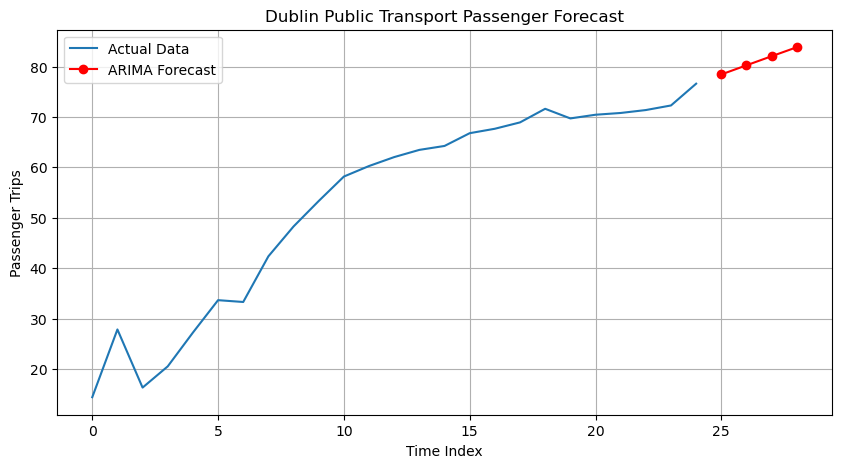

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(df[target_col].dropna(), label='Actual Data')
plt.plot(forecast.index, forecast, label='ARIMA Forecast', color='red', marker='o')
plt.legend()
plt.title('Dublin Public Transport Passenger Forecast')
plt.xlabel('Time Index')
plt.ylabel('Passenger Trips')
plt.grid(True)
plt.show()

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df1 = pd.read_csv('dem-public-transport-journeys.csv')

In [5]:
print("--- dem-public-transport-journeys датаны эхний 5 мөр ---")
display(df1.head())

--- dem-public-transport-journeys датаны эхний 5 мөр ---


,,Total Trips,Bus Eireann,Dublin City Bus,Irish Rail,Luas
0,Q2 20,14.41,0.46,10.11,1.61,2.23
1,Q3 20,27.85,0.81,19.27,2.75,5.03
2,Q4 20,16.32,0.48,13.38,0.89,1.57
3,Q1 21,20.53,0.68,14.98,2.00,2.87
4,Q2 21,27.23,0.90,18.43,3.10,4.80


In [6]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0                    25 non-null     object 
 1   Total Trips      25 non-null     float64
 2   Bus Eireann      25 non-null     float64
 3   Dublin City Bus  25 non-null     float64
 4   Irish Rail       25 non-null     float64
 5   Luas             25 non-null     float64
dtypes: float64(5), object(1)
memory usage: 1.3+ KB


In [7]:
df1.rename(columns={df1.columns[0]: 'Quarter'}, inplace=True)

In [9]:
df1['Year'] = df1['Quarter'].apply(lambda x: x.split()[-1] if type(x) == str else '')
df1['Season_Type'] = df1['Quarter'].apply(lambda x: x.split()[0] if type(x) == str else '')

In [10]:
display(df1.head())
df1.info()

,Quarter,Total Trips,Bus Eireann,Dublin City Bus,Irish Rail,Luas,Year,Season_Type
0,Q2 20,14.41,0.46,10.11,1.61,2.23,20,Q2
1,Q3 20,27.85,0.81,19.27,2.75,5.03,20,Q3
2,Q4 20,16.32,0.48,13.38,0.89,1.57,20,Q4
3,Q1 21,20.53,0.68,14.98,2.00,2.87,21,Q1
4,Q2 21,27.23,0.90,18.43,3.10,4.80,21,Q2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Quarter          25 non-null     object 
 1   Total Trips      25 non-null     float64
 2   Bus Eireann      25 non-null     float64
 3   Dublin City Bus  25 non-null     float64
 4   Irish Rail       25 non-null     float64
 5   Luas             25 non-null     float64
 6   Year             25 non-null     object 
 7   Season_Type      25 non-null     object 
dtypes: float64(5), object(3)
memory usage: 1.7+ KB


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [12]:
cluster_cols = ['Bus Eireann', 'Dublin City Bus', 'Irish Rail', 'Luas']
X_cluster = df1[cluster_cols]

In [13]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

In [16]:
import os
os.environ['OMP_NUM_THREADS'] = '1'

In [18]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df1['Cluster'] = kmeans.fit_predict(X_scaled)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [19]:
# Silhouette Score ба Davies-Bouldin Index тооцоолох
sil_score = silhouette_score(X_scaled, df1['Cluster'])
db_index = davies_bouldin_score(X_scaled, df1['Cluster'])

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Davies-Bouldin Index: {db_index:.4f}")

Silhouette Score: 0.5770
Davies-Bouldin Index: 0.5270


In [20]:
display(df1[['Quarter', 'Total Trips', 'Cluster']].head(10))

,Quarter,Total Trips,Cluster
0,Q2 20,14.41,1
1,Q3 20,27.85,1
2,Q4 20,16.32,1
3,Q1 21,20.53,1
4,Q2 21,27.23,1
5,Q3 21,33.66,1
6,Q4 21,33.30,1
7,Q1 22,42.36,2
8,Q2 22,48.28,2
9,Q3 22,53.33,2


In [21]:
from statsmodels.tsa.arima.model import ARIMA

In [22]:
ts_data = df1['Total Trips'].astype(float)

In [23]:
model = ARIMA(ts_data, order=(1, 1, 1))
model_fit = model.fit()

In [24]:
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:            Total Trips   No. Observations:                   25
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 -71.334
Date:                Wed, 28 Oct 2026   AIC                            148.667
Time:                        16:22:51   BIC                            152.201
Sample:                             0   HQIC                           149.605
                                 - 25                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9913      0.104      9.567      0.000       0.788       1.194
ma.L1         -0.9277      0.429     -2.164      0.030      -1.768      -0.087
sigma2        21.4641      8.256      2.600      0.0

In [26]:
forecast = model_fit.forecast(steps=4)
print("\n--- future 4 season ---")
print(forecast)


--- future 4 season ---
25    78.431689
26    80.247401
27    82.047277
28    83.831455
Name: predicted_mean, dtype: float64


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

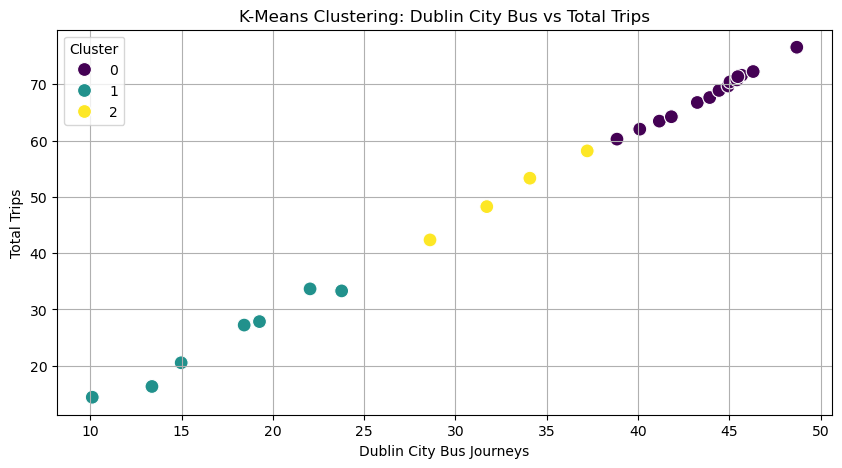

In [28]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df1, x='Dublin City Bus', y='Total Trips', hue='Cluster', palette='viridis', s=100, marker='o')
plt.title('K-Means Clustering: Dublin City Bus vs Total Trips')
plt.xlabel('Dublin City Bus Journeys')
plt.ylabel('Total Trips')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

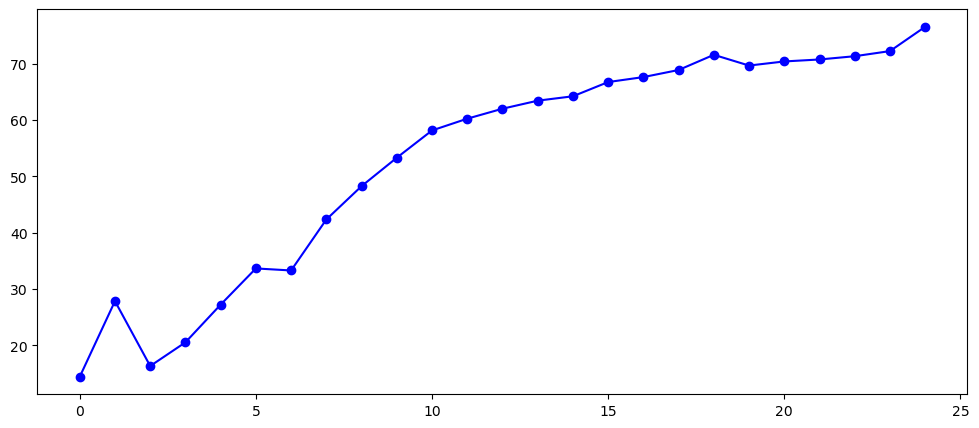

In [30]:
plt.figure(figsize=(12, 5))
plt.plot(df1.index, df1['Total Trips'], label='Actual Trips (real meaning)', color='blue', marker='o')

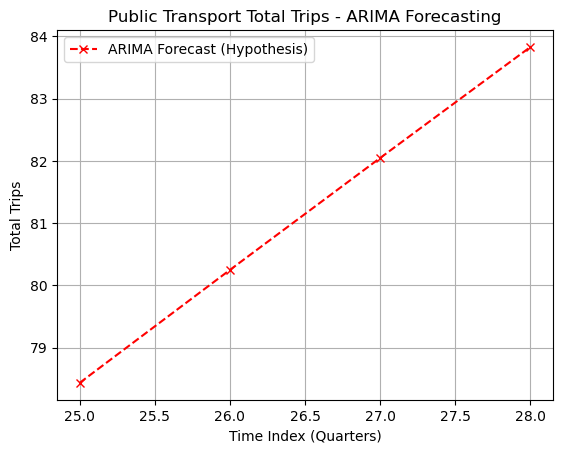

In [32]:
forecast_index = range(len(df1), len(df1) + len(forecast))
plt.plot(forecast_index, forecast, label='ARIMA Forecast (Hypothesis)', color='red', linestyle='--', marker='x')

plt.title('Public Transport Total Trips - ARIMA Forecasting')
plt.xlabel('Time Index (Quarters)')
plt.ylabel('Total Trips')
plt.legend()
plt.grid(True)
plt.show()